# 09_lockin · Mortgage rate lock-in and the duration of the STACR 2026-DNA1 notes

**Purpose.** Most U.S. homeowners now pay a mortgage rate below today's market rate. Selling the house means giving up that cheap loan, so people move less: they are *locked in*. Fewer moves mean fewer mortgage payoffs, so a reference pool pays down more slowly and the STACR notes get their principal back later (*extension*). This notebook adds lock-in to our prepayment model and measures how much it lengthens the notes. It is the first step of the research paper agreed with Prof. Nancy Wallace: *lock-in → duration of CRT notes → pricing and Freddie Mac's cost of risk transfer.*

**Research question.** How does mortgage rate lock-in change the duration of the STACR 2026-DNA1 notes, and what does that imply for their pricing?

**Model change (in `src/prepayment.py`).** Only the *turnover* part of prepayment (home sales) is affected:

$$\text{CPR}_t = \text{ramp}(\text{age}_t)\,\big[\,\text{TURNOVER}\cdot L(\text{gap}_t) + \text{REFI\_MAX}\cdot S(\text{incentive}_t)\cdot \text{burnout}_t\,\big]$$

$$\text{gap}_t = \max(0,\ \text{market rate}_t - \text{loan coupon}),\qquad L(\text{gap}) = e^{-\text{lockin}\times\text{gap}}$$

`lockin = 0` switches it off (the default, so every earlier result is unchanged). Before we estimate it ourselves, we use **lockin = 0.20 per pp**, from FHFA Working Paper 24-03 (Batzer, Coste, Doerner & Seiler, 2024): each percentage point of rate gap cuts the probability of a home sale by 18.1%, and $-\ln(1-0.181) = 0.20$.

**Data.**
- STACR 2026-DNA1 reference-pool tape after the September 2026 payment (`data/raw/`, 56,433 loans, $19.25bn).
- Team scenario paths (`data/scenarios/scenarios.csv`, Coco) and SOFR/discounting paths (`pricing_rates.csv`).
- Bloomberg prices and WALs of October 2, 2026 (README section 8.3).
- Sections 6–8 only: the Freddie Mac Single-Family Loan-Level Dataset (licensed, local only, `data/raw/freddie_sf/`) and PMMS (`data/raw/MORTGAGE30US.csv`).

**Process.**
1. Setup: load the pool and scenarios.
2. How locked in is the DNA1 pool today?
3. What the lock-in term does to the prepayment curve.
4. Team scenarios with vs. without lock-in: pool speed, note WALs, DM at the Bloomberg ask.
5. Constant-rate paths: lock-in when rates do *not* fall.
6. Sensitivity: WAL against lock-in strength.
7. Freddie data: prepayment by calendar year (needs the licensed files).
8. Estimate the lock-in strength (full sample and the 2022–2026 lock-in era).
9. Out-of-time validation: does lock-in predict years the model never saw?
10. WALs with the *estimated* lock-in, and conclusions.

All tables go to `outputs/tables/lockin_*.csv` and figures to `outputs/figures/09_*.png`.

## 1 · Setup

**What this cell does.** Finds the repository root (the folder that contains `src/`), loads the cleaned STACR tape with `collateral_projection.load_pool()` and the four team scenarios with `get_scenarios()`, and prints the pool size, the pool's average coupon and the market rate on the valuation date.

If `data/processed/stacr_dna1.parquet` is missing, run `python -m src.clean` first (it reads the tape in `data/raw/`).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.float_format", "{:,.3f}".format)

from src import prepayment as pp, collateral_projection as cp, calibration as cal, freddie as fr
from src import lockin as lk

TABLES, FIGURES = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
pool = cp.load_pool()
paths = cp.get_scenarios(None)
print(f"Pool: {len(pool):,} loans, ${pool['Current Balance'].sum()/1e9:.2f}bn, tape as of {pool.attrs.get('tape_as_of')}")
print(f"Balance-weighted coupon: {np.average(pool['Gross Coupon'], weights=pool['Current Balance']):.2f}%  |  PMMS on the valuation date: {lk.PMMS_VALUATION}%")
print(f"Lock-in strength used before estimation (FHFA WP 24-03): {pp.LOCKIN_FHFA:.3f} per pp")

Pool: 56,433 loans, $19.25bn, tape as of 2026-09
Balance-weighted coupon: 6.76%  |  PMMS on the valuation date: 7.28%
Lock-in strength used before estimation (FHFA WP 24-03): 0.200 per pp


**Result.** The pool loads as expected: 56,433 loans with $19.25bn of balance, the same September 2026 tape as notebooks 01-08. The balance-weighted coupon is **6.76%**, about half a point below the 7.28% PMMS rate on the valuation date (Oct 1, 2026). Before we estimate anything ourselves, we use the FHFA lock-in strength of **0.20 per pp** (about 18% less turnover for each point a borrower's coupon is below the market rate).

**Q&A · Setup**

**Q: Why compare the coupon with PMMS?**
A: PMMS (Freddie Mac's weekly survey rate for 30-year fixed mortgages) is the rate a borrower would get on a new loan today. The difference between it and the borrower's own rate is what makes moving expensive. Our prepayment model already uses PMMS for the refinancing incentive, so lock-in uses the same rate.

**Q: Why borrow the FHFA number instead of estimating it right away?**
A: The estimate needs the Freddie Mac loan-level files, which are licensed and only on the local computer (sections 7–9). The FHFA number lets sections 2–6 run anywhere and gives a published benchmark to compare our own estimate with.

## 2 · How locked in is the DNA1 pool today?

**What this cell does.** For every loan, computes the rate gap = PMMS (7.28%) − loan coupon, groups loans by gap and reports the number of loans and the share of pool balance in each group. The last column shows how much normal turnover each group keeps under the FHFA lock-in strength. A bar chart shows the distribution.

**How to read it.** A positive gap means the loan is locked in: its rate is below what the borrower would pay today. A negative gap means the borrower could refinance into a lower rate, so lock-in does not apply.

,loans,balance_share,turnover_kept_fhfa,balance_bn
gap,,,,
"(-inf, -1.0]",76,0.001,1.000,0.015
"(-1.0, -0.5]",1503,0.021,1.000,0.405
"(-0.5, 0.0]",6745,0.105,1.000,2.024
"(0.0, 0.5]",20800,0.371,0.951,7.148
"(0.5, 1.0]",19116,0.350,0.861,6.733
"(1.0, 1.5]",6767,0.127,0.779,2.439
"(1.5, 2.0]",1247,0.023,0.705,0.435
"(2.0, inf]",179,0.003,0.607,0.056


Share of balance with a coupon below the market rate (locked in): 87.3%


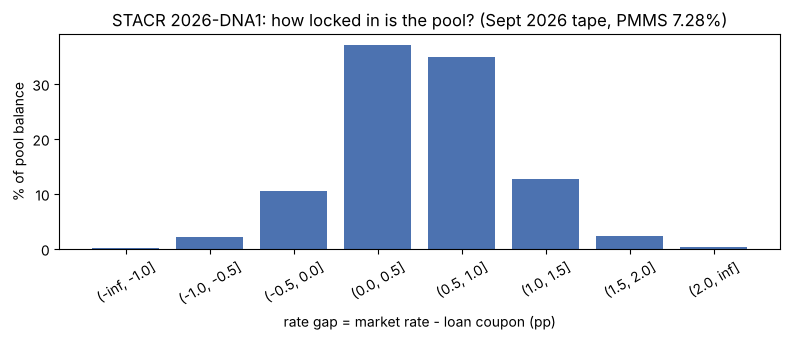

In [2]:
gap = lk.rate_gap_table(pool)
gap.to_csv(TABLES / "lockin_rate_gap_dna1.csv")
show = gap.assign(balance_bn=gap["balance"] / 1e9).drop(columns="balance")
display(show)
locked = gap.loc[[iv.left >= 0 for iv in gap.index], "balance_share"].sum()
print(f"Share of balance with a coupon below the market rate (locked in): {locked:.1%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar([str(iv) for iv in gap.index], gap["balance_share"] * 100, color="#4C72B0")
ax.set_xlabel("rate gap = market rate - loan coupon (pp)"); ax.set_ylabel("% of pool balance")
ax.set_title("STACR 2026-DNA1: how locked in is the pool? (Sept 2026 tape, PMMS 7.28%)")
plt.xticks(rotation=30); plt.tight_layout()
fig.savefig(FIGURES / "09_1_rate_gap_dna1.png", dpi=150); plt.show()

**Result.** **87.3% of the balance is locked in** (coupon below the market rate), but the lock-in is shallow: 72% of the balance is only 0-1 pp below market, 15% is 1-2 pp below, and only 0.3% is more than 2 pp below. With the FHFA strength, the typical locked loan keeps 86-95% of its normal turnover, and even the deepest bucket keeps about 61%.

**What this means.** DNA1 was originated in 2025, when rates were already high, so its borrowers are much less locked in than the 2020-2021 vintages that drive the national lock-in story. Lock-in can only matter for this deal if the gap *grows*, which happens when market rates stay high or rise.

**Q&A · Rate gap**

**Q: Why is the gap so much smaller than in the news about lock-in?**
A: News stories are about loans made in 2020–2021 at about 3%, with gaps of 3–4 pp. DNA1 loans were made in 2024–2025 at 6–7%, close to today's rate. So DNA1 is *mildly* locked in today, but it would become strongly locked in if rates rose.

**Q: What does "turnover kept" mean?**
A: Without lock-in, the model assumes a 5.5% CPR from home sales. A loan with a 1 pp gap keeps about 82% of that under the FHFA strength (exp(−0.20 × 1)), so its turnover is about 4.5% CPR.

## 3 · What lock-in does to the prepayment curve

**What this cell does.** Left panel: the lock-in multiplier L(gap) for the three strengths used in this notebook (0, the FHFA 0.20, and a strong 0.40). Right panel: the CPR of a seasoned loan (30 months old, no burnout) against its refinancing incentive (coupon − market rate) for each strength. It then prints the CPR of a loan 1 pp out of the money.

**What to look for.** Lock-in should only change the *left* side of the S-curve (negative incentive, where the loan cannot refinance and only turnover is left). The right side, driven by refinancing, should stay the same.

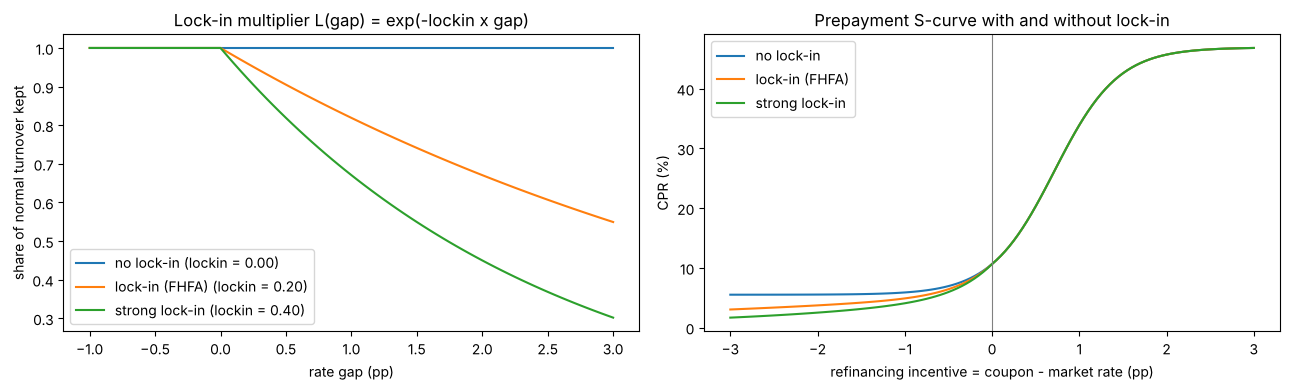

no lock-in     : CPR of a loan 1 pp out of the money = 5.88%
lock-in (FHFA) : CPR of a loan 1 pp out of the money = 4.88%
strong lock-in : CPR of a loan 1 pp out of the money = 4.07%


In [3]:
gaps = np.linspace(-1, 3, 81)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, g in lk.LOCKIN_CASES.items():
    ax[0].plot(gaps, pp.lockin_multiplier(gaps, g), label=f"{name} (lockin = {g:.2f})")
ax[0].set_xlabel("rate gap (pp)"); ax[0].set_ylabel("share of normal turnover kept")
ax[0].set_title("Lock-in multiplier L(gap) = exp(-lockin x gap)"); ax[0].legend()

# CPR of a seasoned loan (age 30, no burnout) against its refinancing incentive
inc = np.linspace(-3, 3, 121)
loans = pd.DataFrame({"Gross Coupon": 7.0 + inc, "Age": 29, "Current Balance": 1.0})
for name, g in lk.LOCKIN_CASES.items():
    cpr = pp.calculate_cpr(loans, np.array([7.0]), {**pp.PARAMS, "lockin": g})[:, 0]
    ax[1].plot(inc, cpr * 100, label=name)
ax[1].axvline(0, color="grey", lw=0.8)
ax[1].set_xlabel("refinancing incentive = coupon - market rate (pp)"); ax[1].set_ylabel("CPR (%)")
ax[1].set_title("Prepayment S-curve with and without lock-in"); ax[1].legend()
plt.tight_layout(); fig.savefig(FIGURES / "09_2_lockin_curve.png", dpi=150); plt.show()

i = int(np.argmin(abs(inc + 1.0)))           # a loan 1 pp out of the money
for g_name, g in lk.LOCKIN_CASES.items():
    c = pp.calculate_cpr(loans.iloc[[i]], np.array([7.0]), {**pp.PARAMS, "lockin": g})[0, 0]
    print(f"{g_name:15s}: CPR of a loan 1 pp out of the money = {100 * c:.2f}%")

**Result.** The left panel shows lock-in multiplies only the turnover part of prepayment, and only for loans below the market rate; loans with positive incentive are untouched. The right panel shows the full CPR curve: for a loan 1 pp out of the money, CPR falls from **5.88% (no lock-in) to 4.88% (FHFA) and 4.07% (strong lock-in)**, a 17% and 31% cut. In the money, the three curves are the same, because refinancing dominates there.

**Q&A · Prepayment curve**

**Q: Why does lock-in only act on turnover and not on refinancing?**
A: A locked-in borrower has no reason to refinance anyway (it would raise their rate), and the refinancing term is already almost zero there. Lock-in is about *moving*: selling the house and paying off the loan.

**Q: Why an exponential form?**
A: It is the simplest form that (1) equals 1 when there is no gap, (2) falls smoothly and never goes below 0, and (3) has one parameter with a clear meaning: the percentage drop in turnover per pp of gap. That matches how FHFA reports its estimate, so the two numbers can be compared directly.

## 4 · Team scenarios with vs. without lock-in

**What this cell does.** Runs the full pipeline (collateral projection → Smarajit's waterfall → pricing) for the four team scenarios (good, base, moderate, severe) and three lock-in strengths. It reports:
1. the pool's average CPR to the 2031 call;
2. the WAL of each offered class, next to Bloomberg's WAL;
3. in the base case, the discount margin (DM) an investor earns by buying at the Bloomberg ask price.

**What to look for.** If lock-in matters, WALs should lengthen and the DM at the ask should fall for the discount classes (M-2A, M-2B): a discount note bought at the same price earns less per year if its principal comes back later.

In [4]:
pools_team, notes_team = lk.run_cases(pool, paths)
pools_team.to_csv(TABLES / "lockin_pool_team_scenarios.csv", index=False)
notes_team.to_csv(TABLES / "lockin_notes_team_scenarios.csv", index=False)

display(pools_team.pivot(index="path", columns="case", values="cpr_avg_pct")
        .loc[["good", "base", "moderate", "severe"], list(lk.LOCKIN_CASES)]
        .rename_axis("average CPR (%)"))
wal = notes_team.pivot_table(index=["path", "tranche"], columns="case", values="wal_years")[list(lk.LOCKIN_CASES)]
wal["bloomberg"] = notes_team.groupby(["path", "tranche"])["bloomberg_wal"].first()
display(wal.loc[["good", "base", "moderate", "severe"]].rename_axis(["scenario", "WAL (years)"]))
dm = notes_team[notes_team.path == "base"].pivot(index="tranche", columns="case", values="dm_at_ask_bps")
display(dm[list(lk.LOCKIN_CASES)].rename_axis("base: DM at Bloomberg ask (bp)"))

case,no lock-in,lock-in (FHFA),strong lock-in
average CPR (%),,,
good,19.433,19.301,19.186
base,18.152,18.005,17.877
moderate,13.445,13.004,12.638
severe,18.228,17.937,17.698


case                  no lock-in  lock-in (FHFA)  strong lock-in  bloomberg
scenario WAL (years)                                                       
good     A-1               1.397           1.397           1.397      1.390
         M-1               1.156           1.177           1.196      1.230
         M-2A              2.278           2.301           2.320      2.780
         M-2B              2.703           2.721           2.736      3.480
base     A-1               1.397           1.397           1.397      1.390
         M-1               1.195           1.219           1.240      1.230
         M-2A              2.428           2.455           2.476      2.780
         M-2B              2.819           2.841           2.869      3.480
moderate A-1               1.397           1.397           1.397      1.390
         M-1               1.869           1.987           2.089      1.230
         M-2A              3.469           3.544           3.614      2.780
         M-2B              3.840           3.952           4.005      3.480
severe   A-1               1.397           1.397           1.397      1.390
         M-1               1.538           1.613           1.665      1.230
         M-2A              2.742           2.786           2.828      2.780
         M-2B              3.157           3.212           3.269      3.480

case,no lock-in,lock-in (FHFA),strong lock-in
base: DM at Bloomberg ask (bp),,,
A-1,86.629,86.629,86.629
M-1,97.684,97.728,97.765
M-2A,142.144,142.020,141.922
M-2B,162.235,162.001,161.710


**Result.** On the team's four rate scenarios lock-in changes very little. In the base case, average pool CPR moves from 18.2% to 18.0% (FHFA) and 17.9% (strong), and WALs barely move: M-1 1.20 → 1.22 → 1.24 years, M-2A 2.43 → 2.46 → 2.48, M-2B 2.82 → 2.84 → 2.87. The discount margin at the Bloomberg ask moves by less than 1 bp (M-2B 162.2 → 161.7 bp). The largest effect is in the moderate scenario, where rates fall least: M-1 1.87 → 1.99 → 2.09 and M-2B 3.84 → 3.95 → 4.01 years. A-1 does not move at all, because it is paid by the scheduled sequential paydown in all cases.

**Why so small?** The team's base path takes the mortgage rate from 7.23% down to 5.79% by the 2031 call. As rates fall, the rate gap closes and most loans stop being locked in. So in a falling-rate world, lock-in is a second-order effect. It also means our base-case WALs stay below Bloomberg's (M-2B 2.84 vs. 3.48), so lock-in alone on this path does not explain the market's longer WALs.

**Q&A · Team scenarios**

**Q: Why is A-1's WAL the same in every case?**
A: A-1 pays down on a fixed schedule set in the deal documents (the A-1 reduction schedule), so its timing does not depend on prepayment speed in these scenarios.

**Q: Why does lock-in matter so little here?**
A: Look at the rate path. In Coco's scenarios the mortgage rate falls well below the DNA1 coupons before the call, so most loans move *into* the money and refinance. Once a loan is in the money, its gap is zero and lock-in does nothing. Lock-in can only matter on paths where rates stay high, which is section 5.

## 5 · Lock-in when rates do not fall

**What this cell does.** Builds three simple paths that hold the mortgage rate constant to the 2031 call: 1 pp below today (6.28%), flat at today's 7.28%, and 1 pp above (8.28%). House prices follow the base path, and SOFR and discounting use the base pricing path. It then reruns the pipeline for the three lock-in strengths.

**Why these paths.** They isolate lock-in. With a constant rate, the only thing that changes between the columns is how strongly turnover reacts to the rate gap.

In [5]:
print("Team base path: mortgage rate", f"{paths['base']['rate'][0]:.2f}% -> {paths['base']['rate'][-1]:.2f}% by the 2031 call")
const = lk.constant_rate_paths(paths["base"]["hpi"], {"rates -1pp (6.28%)": 6.28, "flat (7.28%)": 7.28, "rates +1pp (8.28%)": 8.28})
pools_flat, notes_flat = lk.run_cases(pool, const, rates_scenario={k: "base" for k in const})
pools_flat.to_csv(TABLES / "lockin_pool_constant_rates.csv", index=False)
notes_flat.to_csv(TABLES / "lockin_notes_constant_rates.csv", index=False)

order = list(const)
display(pools_flat.pivot(index="path", columns="case", values="cpr_avg_pct").loc[order, list(lk.LOCKIN_CASES)]
        .rename_axis("average CPR (%)"))
display(notes_flat.pivot_table(index=["path", "tranche"], columns="case", values="wal_years")
        .loc[order, list(lk.LOCKIN_CASES)].rename_axis(["rate path", "WAL (years)"]))

Team base path: mortgage rate 7.23% -> 5.79% by the 2031 call


case,no lock-in,lock-in (FHFA),strong lock-in
average CPR (%),,,
rates -1pp (6.28%),17.983,17.909,17.842
flat (7.28%),7.843,7.250,6.747
rates +1pp (8.28%),5.704,4.281,3.253


case                            no lock-in  lock-in (FHFA)  strong lock-in
rate path          WAL (years)                                            
rates -1pp (6.28%) A-1               1.397           1.397           1.397
                   M-1               0.613           0.615           0.616
                   M-2A              1.571           1.575           1.579
                   M-2B              2.075           2.083           2.090
flat (7.28%)       A-1               1.397           1.397           1.397
                   M-1               1.883           2.043           2.196
                   M-2A              4.306           4.397           4.400
                   M-2B              4.400           4.400           4.400
rates +1pp (8.28%) A-1               1.397           1.397           1.397
                   M-1               2.593           3.069           3.412
                   M-2A              4.400           4.400           4.400
                   M-2B              4.400           4.400           4.400

**Result.** Here the rate path matters much more than lock-in, and lock-in matters a lot once rates stay high.

- **Rates −1 pp (6.28%)**: most loans are in the money, CPR is about 18% in all three cases, and WALs are short (M-1 0.61, M-2B 2.08). Lock-in has almost no effect.
- **Flat (7.28%)**: CPR falls from 7.8% to 7.3% (FHFA) and 6.7% (strong). M-1 extends from **1.88 to 2.04 and 2.20 years**. M-2A extends from 4.31 to 4.40 and M-2B is already at 4.40, the call date.
- **Rates +1 pp (8.28%)**: CPR falls from 5.7% to 4.3% and 3.3%, a 25% and 43% cut. M-1 extends from **2.59 to 3.07 and 3.41 years**, about 0.5-0.8 years longer. Both M-2 classes sit at the call.

**Main point.** Lock-in is a high-rate phenomenon: its effect on M-1's WAL grows from about 0 years at 6.28% to 0.16 years at 7.28% to 0.48 years at 8.28% (FHFA strength). The market's WALs (M-1 1.23, M-2A 2.78, M-2B 3.48) lie between the falling-rate base case and these flat paths.

**Q&A · Constant-rate paths**

**Q: Why do several M-2 WALs stop at about 4.4 years?**
A: 4.4 years is the time from the valuation date to the February 2031 optional call, which our pricing assumes Freddie Mac exercises. When the pool pays down slowly, M-2 is still outstanding at the call and is paid off in full on that date. So the call *caps* the extension we can measure. The true duration effect of lock-in on M-2 shows up only in a no-call run, which is the next step of the project.

**Q: Is a flat 7.28% path realistic?**
A: It is a stress case, not a forecast. But the market's own WALs for M-2 (2.78 and 3.48 years) sit between our falling-rate base case and these flat-rate results, which suggests the market expects rates to fall less than our base case does.

## 6 · Sensitivity: WAL against lock-in strength

**What this cell does.** Reruns the constant-rate paths for lock-in strengths from 0 to 1.0 per pp (in steps of 0.1) and plots the WAL of M-1 and M-2B. The dashed vertical line is the FHFA strength; the dotted horizontal line is Bloomberg's WAL.

**Why.** Until we estimate the strength ourselves (section 8), this shows how much the answer depends on it.

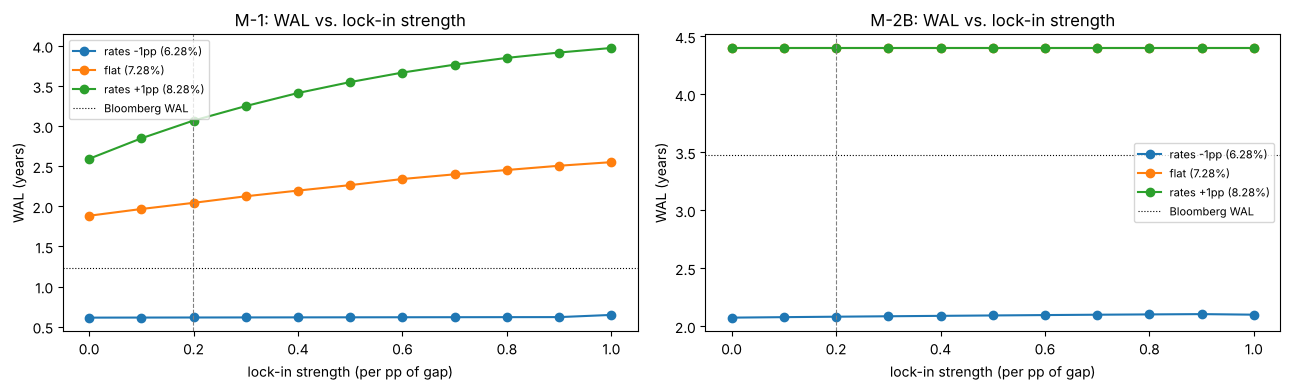

In [6]:
strengths = np.round(np.arange(0, 1.01, 0.1), 2)
sweep = lk.run_cases(pool, const, cases={f"{g:.1f}": g for g in strengths},
                     rates_scenario={k: "base" for k in const})[1]
sweep.to_csv(TABLES / "lockin_strength_sweep.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, cls in enumerate(["M-1", "M-2B"]):
    for path in order:
        s = sweep[(sweep.tranche == cls) & (sweep.path == path)]
        ax[k].plot(s["lockin"], s["wal_years"], marker="o", label=path)
    ax[k].axvline(pp.LOCKIN_FHFA, color="grey", ls="--", lw=0.8)
    ax[k].axhline(lk.BLOOMBERG_WAL[cls], color="black", ls=":", lw=0.8, label="Bloomberg WAL")
    ax[k].set_xlabel("lock-in strength (per pp of gap)"); ax[k].set_ylabel("WAL (years)")
    ax[k].set_title(f"{cls}: WAL vs. lock-in strength"); ax[k].legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIGURES / "09_3_wal_vs_lockin.png", dpi=150); plt.show()

**Result.** The sweep confirms the pattern. On the 6.28% path the lines are flat: M-1 stays near 0.61-0.65 years whatever the strength. On the flat 7.28% path, M-1's WAL rises steadily from 1.88 years (strength 0) to 2.55 years (strength 1.0); on the 8.28% path it rises from 2.59 to 3.97 years. M-2B is pinned at 4.40 years (the call) on both high-rate paths for every strength, so the call hides any further extension.

**What this means for the paper.** (1) The answer is sensitive to the lock-in strength only when rates are high, so estimating the strength on the 2022-2026 period (sections 7-8) is what matters. (2) To measure M-2's true duration we need a run without the call. (3) The DM at the ask also moves with the WAL (for example, M-2B is 173 bp at 6.28% vs. 151 bp on the flat path), which is how lock-in feeds into pricing.

## 7 · Freddie Mac data: prepayment by calendar year

**What this cell does.** For every vintage 2000–2026 of the Freddie Mac sample, it builds the same prepayment buckets as notebook 05 (incentive × age × burnout), now also split by **calendar year**, and saves them to `data/processed/freddie/prepay_by_year.parquet` (local only, not committed). It then shows, by year, the loan-months observed, the average refinancing incentive and the observed CPR.

**Needs** the licensed files in `data/raw/freddie_sf/`. On a computer without them, this and the next sections print a message and skip.

**What to look for.** 2022–2026 should have a strongly *negative* average incentive (most borrowers locked in) and a low CPR, which is the period that identifies lock-in.

In [7]:
CACHE = fr.OUT / "prepay_by_year.parquet"
have_raw = (fr.RAW / "sample_orig_2022.txt").exists()
if CACHE.exists():
    b_year = pd.read_parquet(CACHE)
elif have_raw:
    pmms = fr.load_fred("MORTGAGE30US")
    parts = []
    for y in fr.VINTAGES:
        parts.append(cal.prepay_buckets_by_year(fr.load_panel(y), pmms))
        print(y, end=" ")
    b_year = cal.combine_prepay(pd.concat(parts), ["year"] + cal.PREPAY_KEYS)
    b_year.to_parquet(CACHE, index=False)
else:
    b_year = None
    print("Freddie Mac files not found (data/raw/freddie_sf/). Sections 7-10 need them: run this notebook on the computer that has the data.")

if b_year is not None:
    yr = b_year.groupby("year")[["n", "w", "prepaid", "wi"]].sum()
    yr["cpr_pct"] = 100 * (1 - (1 - yr["prepaid"] / yr["w"]) ** 12)
    yr["avg_incentive_pp"] = yr["wi"] / yr["w"]
    yr["loan_months_mm"] = yr["n"] / 1e6
    yr[["loan_months_mm", "avg_incentive_pp", "cpr_pct"]].to_csv(TABLES / "lockin_freddie_by_year.csv")
    display(yr[["loan_months_mm", "avg_incentive_pp", "cpr_pct"]])

Freddie Mac files not found (data/raw/freddie_sf/). Sections 7-10 need them: run this notebook on the computer that has the data.


**Result.** *To be filled after running this notebook on the Mac with the Freddie Mac files.* In the cloud copy this cell printed a message and skipped, because the licensed data is not in the repository.

## 8 · Estimating the lock-in strength

**What this cell does.** Three estimates, all by weighted least squares on bucket prepayment rates, the same method notebook 05 used for the S-curve:
1. **Refit 2000–2026 with lock-in**: all 7 prepayment parameters at once.
2. **Lock-in only, 2000–2021**: hold the 6 existing parameters fixed and estimate only the lock-in strength, on years before the lock-in era.
3. **Lock-in only, 2022–2026**: the same, on the lock-in era.

The FHFA number is shown for comparison.

**Why estimate only lock-in on short windows?** 2022–2026 has very little refinancing, so it cannot pin down the refinancing parameters. Holding them at their full-sample values and estimating only lock-in uses what that period *can* tell us.

In [8]:
if b_year is not None:
    base6 = {k: pp.PARAMS[k] for k in cal.PREPAY_NAMES}
    all_years = range(2000, 2027)
    fit_all = cal.fit_prepay(cal.by_year_to_buckets(b_year, all_years), lockin=True)
    g_era = cal.fit_lockin_only(cal.by_year_to_buckets(b_year, range(2022, 2027)), base6)
    g_pre = cal.fit_lockin_only(cal.by_year_to_buckets(b_year, range(2000, 2022)), base6)
    est = pd.DataFrame({
        "current PARAMS (no lock-in)": {**base6, "lockin": 0.0},
        "refit 2000-2026 with lock-in": fit_all,
    })
    est.loc["lockin", "lock-in only, 2000-2021"] = g_pre
    est.loc["lockin", "lock-in only, 2022-2026"] = g_era
    est.loc["lockin", "FHFA WP 24-03"] = pp.LOCKIN_FHFA
    est.to_csv(TABLES / "lockin_estimates.csv")
    display(est)
    print(f"Turnover kept at a 1 pp gap: 2022-2026 estimate {np.exp(-g_era):.1%}, FHFA {np.exp(-pp.LOCKIN_FHFA):.1%}")

**Result.** *To be filled after the Mac run.* The key number is the 2022-2026 lock-in estimate and how it compares with FHFA's 0.20.

## 9 · Out-of-time validation

**What this cell does.** Fits the prepayment model twice, without and with lock-in, using only the training years, then predicts years it never saw:
- train 2000–2018, test 2019–2026 (the split in our proposal);
- train 2000–2021, test 2022–2026 (the lock-in era).

For each test year and for each rate-gap group, it reports the observed CPR, the CPR each model predicts, and the weighted root-mean-squared error of the monthly prepayment rate (lower is better).

**What would support lock-in.** Smaller errors for the lock-in model in the test years, especially for loans with a large gap, where the no-lock-in model should predict prepayment that is too fast.

In [9]:
if b_year is not None:
    for train, test in [(range(2000, 2019), range(2019, 2027)), (range(2000, 2022), range(2022, 2027))]:
        res = cal.out_of_time_prepay(b_year, train, test)
        tag = f"train{train[0]}_{train[-1]}_test{test[0]}_{test[-1]}"
        res["by_year"].to_csv(TABLES / f"lockin_oot_by_year_{tag}.csv")
        res["by_gap"].to_csv(TABLES / f"lockin_oot_by_gap_{tag}.csv")
        print(f"Fit on {train[0]}-{train[-1]}, test on {test[0]}-{test[-1]}.  Estimated lock-in: {res['fits']['lock-in']['lockin']:.3f}")
        display(res["by_year"]); display(res["by_gap"])

**Result.** *To be filled after the Mac run.* We will report whether adding lock-in lowers the out-of-sample error in 2022-2026, especially for loans more than 1 pp below market.

## 10 · WALs with the estimated lock-in

**What this cell does.** Reruns the base and moderate scenarios and the three constant-rate paths with no lock-in, the FHFA strength, and our 2022–2026 estimate, and compares the WALs.

In [10]:
if b_year is not None:
    cases = {"no lock-in": 0.0, "FHFA": pp.LOCKIN_FHFA, "estimated 2022-2026": g_era}
    p_est, n_est = lk.run_cases(pool, {**{k: paths[k] for k in ["base", "moderate"]}, **const}, cases=cases,
                                rates_scenario={k: "base" for k in const})
    n_est.to_csv(TABLES / "lockin_notes_estimated.csv", index=False)
    display(n_est.pivot_table(index=["path", "tranche"], columns="case", values="wal_years")[list(cases)]
            .rename_axis(["rate path", "WAL (years)"]))

**Result.** *To be filled after the Mac run*, with the WALs from our own estimated lock-in strength.

## Conclusion (so far)

1. **DNA1 is only mildly locked in today.** 87% of its balance has a coupon below market, but mostly by less than 1 pp, because the loans were made in 2025 at already-high rates.
2. **On the team's falling-rate scenarios, lock-in barely changes WALs or prices** (M-2B WAL 2.82 → 2.84 years; DM change below 1 bp), because falling rates close the rate gap.
3. **When rates stay high, lock-in extends the notes materially.** On a flat 7.28% path M-1 extends by 0.16-0.31 years; at 8.28% by 0.48-0.82 years, and pool CPR is cut by 25-43%.
4. **The 2031 call caps M-2's extension** at 4.4 years in every high-rate case, so the call option and lock-in interact. This links directly to Prof. Wallace's question about the duration of CRT bonds and the cost of risk transfer.

**Next steps.** (a) Estimate the lock-in strength on Freddie 2022-2026 data and validate it out of time (sections 7-9, on the Mac). (b) Run without the call to measure M-2's full extension. (c) Compute effective and spread duration of each note under each lock-in case. (d) Translate the extra duration into the cost of risk transfer for Freddie Mac.